# 01 — Reinforcement learning fundamentals

## Learning objectives

- Describe states/actions/rewards, MDP transitions and policies.
- Calculate returns, values and Bellman recursions.
- Run actual state-dependent Q-learning instead of a stateless reward dictionary.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** RL_Fundamental.ipynb dictionary/DQN/racing demos; RLHF PDF crossroad Q10/50/20 and DQN target10.4; notes Chapter01. Originals read from Git without restoring missing working-tree files.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## From game interaction to an MDP
An MDP is $(S,A,P,r,d_0,\gamma)$. $S$ is states, $A$ actions, $P(s'\mid s,a)$ next-state probability, $r(s,a)$ expected immediate reward, $d_0$ starting-state distribution and $\gamma$ discount. Markov means the state retains relevant predictive information. Here the game state is chain position; the agent chooses left/right. A stochastic policy samples moves; a deterministic policy chooses one move per state. An episode ends at a terminal endpoint or a time limit.

$$
G_t=\sum_{k=0}^{T-1-t}\gamma^kR_{t+k},\qquad V^\pi(s)=\mathbb E[G_t\mid s_t=s],\qquad Q^\pi(s,a)=\mathbb E[G_t\mid s_t=s,a_t=a].
$$
$R_t$ is reward after action $t$, $T$ episode length, and $G_t$ remaining return. $V$ averages actions under policy $\pi$; $Q$ fixes the first action. Discount $\gamma$ controls future weighting. For rewards $[0,0,10]$ at $\gamma=.9$, $G_0=8.1$.

$$
Q^\pi(s,a)=r(s,a)+\gamma\sum_{s'}P(s'\mid s,a)V^\pi(s'),\qquad V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a).
$$
Split $G_t=R_t+\gamma G_{t+1}$ to derive Bellman expectation. Optimality replaces the next-state action average with $\max_{a'}Q^*(s',a')$. Terminal values are zero; a time-limit observation can still bootstrap.

In [2]:
# Synthetic chain: positions 0..4, start 2, left/right actions, terminal endpoints.
# Goal 4 earns +1; endpoint 0 earns -1; each intermediate step costs .02.
class Chain:
    def reset(self):self.position=2;self.steps=0;return self.position
    def step(self,action):
        self.steps+=1;self.position+=1 if action else -1
        terminated=self.position in (0,4);truncated=self.steps>=12 and not terminated
        reward=1. if self.position==4 else -1. if self.position==0 else -.02
        return self.position,reward,terminated,truncated

def state_tensor(states):return F.one_hot(torch.as_tensor(states),num_classes=5).float()
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__();self.shared=nn.Sequential(nn.Linear(5,24),nn.Tanh());self.actor=nn.Linear(24,2);self.critic=nn.Linear(24,1)
    def forward(self,states):
        h=self.shared(state_tensor(states));return torch.distributions.Categorical(logits=self.actor(h)),self.critic(h).squeeze(-1)

In [3]:
def discounted_returns(rewards,gamma=.9):
    result=[];carry=0.
    for reward in reversed(rewards):carry=reward+gamma*carry;result.append(carry)
    return list(reversed(result))
assert np.allclose(discounted_returns([0,0,10]),[8.1,9.,10.])
# Source crossroad example, not measured experiment data.
q=np.array([10.,50.,20.]);pi=np.array([.2,.5,.3]);value=pi@q
assert value==33 and abs(pi@(q-value))<1e-10
print('Crossroad value:',value,'advantages:',q-value)
# Bellman expectation via linear system on nonterminal states, uniform policy.
P=np.zeros((3,3));reward=np.zeros(3)
for s in range(1,4):
    for action in (0,1):
        ns=s+(1 if action else -1);r=1 if ns==4 else -1 if ns==0 else -.02
        reward[s-1]+=.5*r
        if ns not in (0,4):P[s-1,ns-1]+=.5
V=np.linalg.solve(np.eye(3)-.95*P,reward)
assert np.allclose(V,reward+.95*P@V)
print('Exact uniform-policy state values:',V)

Crossroad value: 33.0 advantages: [-23.  17. -13.]
Exact uniform-policy state values: [-0.53553531 -0.05375854  0.46446469]


## Q-learning implementation

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\left[R+\gamma(1-d)\max_{a'}Q(s',a')-Q(s,a)\right].
$$
$\alpha$ is step size, $d$ true termination, and the bracket is TD error. This off-policy target uses the best next action even when epsilon-greedy behavior explored. SARSA would use the actual next sampled action. Monte Carlo waits for full return; TD bootstraps an estimate. Unlike the original dictionary demo, the code below has transitions, future value and a changing exploration policy.

Learned Q: [[ 0.          0.        ]
 [-0.8031256   0.84239038]
 [ 0.72519705  0.93      ]
 [ 0.82971795  1.        ]
 [ 0.          0.        ]] greedy nonterminal actions: [1 1 1]


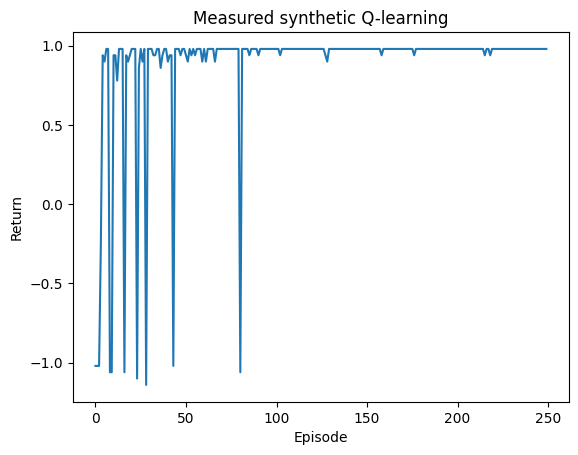

In [4]:
Q=np.zeros((5,2));env=Chain();returns=[]
for episode in range(250):
    state=env.reset();total=0.;epsilon=max(.05,.8*(.985**episode))
    while True:
        action=random.randrange(2) if random.random()<epsilon else int(Q[state].argmax())
        next_state,reward,done,truncated=env.step(action)
        target=reward+.95*(not done)*Q[next_state].max()
        Q[state,action]+=.15*(target-Q[state,action]);total+=reward
        if done or truncated:break
        state=next_state
    returns.append(total)
print('Learned Q:',Q,'greedy nonterminal actions:',Q[1:4].argmax(-1))
plt.plot(returns);plt.xlabel('Episode');plt.ylabel('Return');plt.title('Measured synthetic Q-learning');plt.show()
assert np.all(Q[1:4].argmax(-1)==1)

## Mapping to LLMs

State = prompt plus prefix; action = next token; policy = LM probability distribution; trajectory = response; terminal = EOS/stopping condition. Response reward can be terminal or token-shaped. A reward dictionary is not a full LLM RL implementation.

## Exercises

1. Change the terminal rewards and predict the policy before training.
2. Implement SARSA and compare exploratory trajectories.
3. Recompute the Bellman system for a biased policy.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.